# NBM

In [1]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
# cityName = 'Memphis, TN (KMEM)'
# points = pd.DataFrame({"longitude": [-90.04898], "latitude": [35.14953]})


In [2]:
# Determine the latest model cycle (uses functions.get_latest_forecast_cycle)
init_nbm = get_latest_forecast_cycle(model="IFS")

# Determine forecast steps to request (uses functions.calculate_forecast_range)
fxx_nbm = calculate_forecast_range(init_nbm, model="IFS")

H_nbm = FastHerbie([init_nbm], model="NBM", product="co", fxx=fxx_nbm)

# H_nbm.inventory(":TMP:2 m.*:nan:nan")

In [3]:
fxx_nbm


[27, 30, 33, 36, 39, 42, 45, 48, 51]

In [4]:
fxx_nbm

[15, 18, 21, 24, 27, 30, 33, 36, 39]

In [5]:
H_nbm.inventory(":APCP:")
H_nbm.inventory(":APCP:surface:14-15 hour acc fcst:nan:nan")
H_nbm.download(":APCP:")
H_nbm.xarray(":APCP:surface:14-15 hour acc fcst:", backend_kwargs={'decode_times': False})

/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/herbie/core.py:1114: UserWarning: Will not remove GRIB file because it previously existed.
  warnings.warn("Will not remove GRIB file because it previously existed.")
🦨 No subsets found with search=':APCP:surface:14-15 hour acc fcst:' in self.model='nbm' self.date=Timestamp('2025-09-11 12:00:00') self.fxx=18


FileNotFoundError: [Errno 2] No such file or directory: '/Users/jglarson/data/nbm/20250911/subset_ca89b1fe__blend.t12z.core.f018.co.grib2'

In [ ]:
container = np.empty(len(fxx_nbm), dtype=object)
for i in range(len(fxx_nbm)):
    pattern = f":APCP:surface:{fxx_nbm[i]-1}-{fxx_nbm[i]} hour acc fcst:nan:nan"
    print(pattern)
    print(H_nbm.inventory(pattern)['forecast_time'])
    container[i] = H_nbm.xarray(pattern, backend_kwargs={'decode_times': False}).herbie.pick_points(points, method="nearest")['tp']

ds_nbm = xr.concat(container, dim='time')

:APCP:surface:14-15 hour acc fcst:nan:nan
0    14-15 hour acc fcst
Name: forecast_time, dtype: object
👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20250911]


🦨 No subsets found with search=':APCP:surface:14-15 hour acc fcst:nan:nan' in self.model='nbm' self.date=Timestamp('2025-09-11 12:00:00') self.fxx=18


FileNotFoundError: [Errno 2] No such file or directory: '/Users/jglarson/data/nbm/20250911/subset_ca89b1fe__blend.t12z.core.f018.co.grib2'

In [ ]:
H_nbm.xarray(":APCP:surface:", backend_kwargs={'decode_times': False}).herbie.pick_points(points, method="nearest")['tp']

In [142]:
# H_nbm.inventory(":APCP:surface:")
H_nbm.xarray(":APCP:surface:", backend_kwargs={'decode_times': False}).herbie.pick_points(points, method="nearest")['tp']

<xarray.DataArray 'tp' (step: 9, point: 1)> Size: 36B
array([[ 5.   ],
       [11.   ],
       [27.   ],
       [21.   ],
       [ 0.254],
       [15.   ],
       [ 0.   ],
       [ 4.   ],
       [ 0.   ]], dtype=float32)
Coordinates:
    time                 int64 8B 1757030400
  * step                 (step) timedelta64[ns] 72B 1 days 03:00:00 ... 2 day...
    surface              float64 8B 0.0
    latitude             (point) float64 8B 35.15
    longitude            (point) float64 8B 269.9
    valid_time           (step) float64 72B 1.757e+09 1.757e+09 ... 1.757e+09
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 8B 0.3256
    point_longitude      (point) float64 8B -90.05
    point_latitude       (point) float64 8B 35.15
Dimensions without coordinates: point
Attributes: (12/38)
    GRIB_paramId:                             228228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      3744965
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_shortName:                           tp
    GRIB_units:                               kg m**-2
    long_name:                                Total Precipitation
    units:                                    kg m**-2
    standard_name:                            unknown
    grid_mapping:                             gribfile_projection

In [ ]:
# 2 m temperature: extract, convert K->F, compute max/min for the point
t2m_nbm = H_nbm.xarray(":TMP:2 m.*:nan:nan", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]  # skip first timestep which is included for precip only
t2m_nbm = (t2m_nbm - 273.15) * 1.8 + 32
tmax_nbm = float(t2m_nbm.max().values)
tmin_nbm = float(t2m_nbm.min().values)
init_times_nbm = convert_time_to_datetime64(t2m_nbm.time.values)
valid_times_nbm = convert_time_to_datetime64(t2m_nbm.valid_time.values)

# 10 m wind speed (HRRR exposes :WIND / si10)
si10_nbm = H_nbm.xarray(":WIND:10 m above ground:", backend_kwargs={'decode_times': False}
                            ).herbie.pick_points(points, method="nearest")['max_10si'].sel(point=0)[1:]  # skip first timestep which is included for precip only
wind_max_nbm = float(si10_nbm.max().values) * 1.94384 # convert from m/s to knots

# Total precipitation from APCP (convert mm -> in); compute 24h accumulation as in prior script
tp_nbm = H_nbm.xarray("APCP", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
tp_nbm = tp_nbm * 0.0393701   # mm -> inches (1 mm -> 0.0393701 in)

# Subtract first timestep to get accumulation over the requested period (as in original)
tp_nbm = tp_nbm[1:] - tp_nbm[0]
precip_nbm = float(tp_nbm.max().values)

# build and print a simple table using pandas for formatting (NBM)
df = pd.DataFrame({
    "Model": ["NBM"],
    "High (°F)": [round(tmax_nbm, 2)],
    "Low (°F)": [round(tmin_nbm, 2)],
    "Precipitation (in)": [round(precip_nbm, 3)],
    "Wind Speed (kt)": [round(wind_max_nbm, 2)],
    "Model Init": [pd.Timestamp(init_times_nbm).isoformat()],
    "Valid Range": [f"{valid_times_nbm[0]} - {valid_times_nbm[-1]}"]
})

title = f"Forecasting for {cityName} (NBM)"
print(title)
print(df.to_string(index=False))


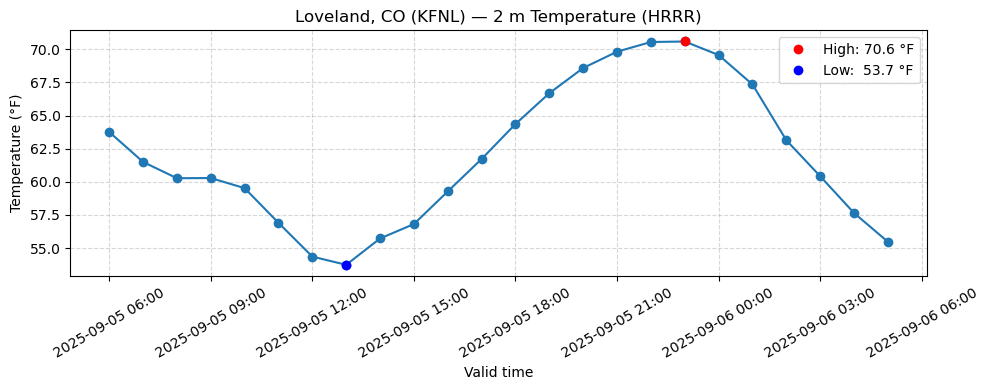

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

times = pd.to_datetime(valid_times_hrrr)  # numpy.datetime64 -> DatetimeIndex
temps = t2m_hrrr.values  # Fahrenheit values from HRRR

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(times, temps, marker='o', linestyle='-')

# highlight max/min
idx_max = int(np.nanargmax(temps))
idx_min = int(np.nanargmin(temps))
ax.plot(times[idx_max], temps[idx_max], 'ro', label=f"High: {temps[idx_max]:.1f} °F")
ax.plot(times[idx_min], temps[idx_min], 'bo', label=f"Low:  {temps[idx_min]:.1f} °F")

ax.set_title(f"{cityName} — 2 m Temperature (HRRR)")
ax.set_xlabel("Valid time")
ax.set_ylabel("Temperature (°F)")
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# AIFS

In [48]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
# cityName = 'Eagle, CO (KEGE)'
# points = pd.DataFrame({"longitude": [-106.9156], "latitude": [39.6426]})

print("Fetching AIFS data...")

init_aifs = get_latest_forecast_cycle(model="AIFS")
fxx_aifs = calculate_forecast_range(init_aifs, model="AIFS")
H_aifs = FastHerbie([init_aifs], model="aifs", product="oper", fxx=fxx_aifs)

# 2 m temperature: extract and convert
t2m_aifs = H_aifs.xarray(":2t:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]  # skip first timestep which is included for precip only
t2m_aifs = (t2m_aifs - 273.15) * 1.8 + 32
tmax_aifs = float(t2m_aifs.max().values)
tmin_aifs = float(t2m_aifs.min().values)
init_times_aifs = convert_time_to_datetime64(t2m_aifs.time.values)
valid_times_aifs = convert_time_to_datetime64(t2m_aifs.valid_time.values)

# Wind from components -> magnitude
u10_aifs = H_aifs.xarray(":10u:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['u10'].sel(point=0)[1:]  # skip first timestep which is included for precip only
v10_aifs = H_aifs.xarray(":10v:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['v10'].sel(point=0)[1:]  # skip first timestep which is included for precip only
wind_max_aifs = float((np.sqrt(u10_aifs**2 + v10_aifs**2)).max().values) * 1.94384 # Convert m/s to knots

# Total precipitation (sum over requested steps) and convert to inches
tp_aifs = H_aifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
precip_aifs = float(tp_aifs.values) * 39.3701 # Convert meters to inches (1 m -> 39.3701 in)



Fetching AIFS data...
👨🏻‍🏭 Created directory: [/Users/jglarson/data/aifs/20250916]
INFO: 🌱 Growing new BallTree...🌳 BallTree grew in 0.62 seconds.
INFO: Saved BallTree to /Users/jglarson/data/BallTree/aifs_1440-721.pkl


TypeError: only length-1 arrays can be converted to Python scalars

In [49]:
tp_aifs

<xarray.DataArray 'tp' (step: 5)> Size: 20B
array([3.1640625, 3.5214844, 3.5429688, 4.7851562, 6.3945312],
      dtype=float32)
Coordinates:
    time                 int64 8B 1758045600
  * step                 (step) timedelta64[ns] 40B 0 days 12:00:00 ... 1 day...
    surface              float64 8B 0.0
    latitude             float64 8B 40.5
    longitude            float64 8B -105.0
    valid_time           (step) float64 40B 1.758e+09 1.758e+09 ... 1.758e+09
    gribfile_projection  object 8B None
    point_grid_distance  float64 8B 5.384
    point_longitude      float64 8B -105.0
    point_latitude       float64 8B 40.45
Attributes: (12/34)
    GRIB_paramId:                             228228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_shortName:                           tp
    GRIB_units:                               kg m**-2
    long_name:                                Total Precipitation
    units:                                    kg m**-2
    standard_name:                            unknown
    grid_mapping:                             gribfile_projection

In [46]:
init_aifs

Timestamp('2025-09-16 18:00:00')

In [40]:
# Create the title and the table combining both models (use the current variable names)
title = f"Forecasting for {cityName} \nValid: {str(valid_times_aifs[0])} - {str(valid_times_aifs[-1])} UTC"

data = {
    "Model": ["AIFS"],
    "High (°F)": [tmax_aifs],
    "Low (°F)": [tmin_aifs],
    "Precipitation (in)": [precip_aifs],
    "Wind Speed (kt)": [wind_max_aifs],
    "Model Init": [f"{str(init_times_aifs)} UTC"]
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))


Forecasting for Eagle, CO (KEGE) 
Valid: 2025-09-17T12 - 2025-09-18T06 UTC
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)        Model Init
 AIFS      57.32     36.56              545.49              3.3 2025-09-16T18 UTC


# IFS

In [30]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
# cityName = 'Eagle, CO (KEGE)'
# points = pd.DataFrame({"longitude": [-106.9156], "latitude": [39.6426]})

print("Fetching IFS data...")

init_ifs = get_latest_forecast_cycle(model="IFS")
fxx_ifs = calculate_forecast_range(init_ifs, model="IFS")
H_ifs = FastHerbie([init_ifs], model="ifs", product="oper", fxx=fxx_ifs)

# 2 m temperature: extract and convert
t2m_ifs = H_ifs.xarray(":2t:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]  # skip first timestep which is included for precip only
t2m_ifs = (t2m_ifs - 273.15) * 1.8 + 32
tmax_ifs = float(t2m_ifs.max().values)
tmin_ifs = float(t2m_ifs.min().values)
init_times_ifs = convert_time_to_datetime64(t2m_ifs.time.values)
valid_times_ifs = convert_time_to_datetime64(t2m_ifs.valid_time.values)

# Wind from components -> magnitude
u10_ifs = H_ifs.xarray(":10u:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['u10'].sel(point=0)[1:]  # skip first timestep which is included for precip only
v10_ifs = H_ifs.xarray(":10v:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['v10'].sel(point=0)[1:]  # skip first timestep which is included for precip only
wind_max_ifs = float((np.sqrt(u10_ifs**2 + v10_ifs**2)).max().values) * 1.94384 # Convert m/s to knots

# Total precipitation (sum over requested steps) and convert to inches
tp_ifs = H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
precip_ifs = float(tp_ifs.sum().values) * 39.3701 # Convert meters to inches (1 m -> 39.3701 in)

times_ifs = pd.to_datetime(valid_times_ifs)



Fetching IFS data...
👨🏻‍🏭 Created directory: [/Users/jglarson/data/ifs/20250916]
INFO: 🌱 Growing new BallTree...🌳 BallTree grew in 0.87 seconds.
INFO: Saved BallTree to /Users/jglarson/data/BallTree/ifs_1440-721.pkl


In [34]:
H_ifs.inventory(":tp:")

,grib_message,start_byte,end_byte,range,reference_time,valid_time,step,param,levelist,levtype,number,domain,expver,class,type,stream,search_this,FILE
0,22,16665694,17448756,16665694-17448756,2025-09-16 12:00:00,2025-09-17 06:00:00,0 days 18:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
1,20,14441649,15250926,14441649-15250926,2025-09-16 12:00:00,2025-09-17 09:00:00,0 days 21:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
2,14,9752090,10584371,9752090-10584371,2025-09-16 12:00:00,2025-09-17 12:00:00,1 days 00:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
3,22,16264604,17117721,16264604-17117721,2025-09-16 12:00:00,2025-09-17 15:00:00,1 days 03:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
4,18,13921232,14792361,13921232-14792361,2025-09-16 12:00:00,2025-09-17 18:00:00,1 days 06:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
5,23,17933801,18820750,17933801-18820750,2025-09-16 12:00:00,2025-09-17 21:00:00,1 days 09:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
6,16,10704323,11605664,10704323-11605664,2025-09-16 12:00:00,2025-09-18 00:00:00,1 days 12:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
7,17,11818286,12733539,11818286-12733539,2025-09-16 12:00:00,2025-09-18 03:00:00,1 days 15:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...
8,16,11508824,12438153,11508824-12438153,2025-09-16 12:00:00,2025-09-18 06:00:00,1 days 18:00:00,tp,NaN,sfc,NaN,g,0001,od,fc,oper,:tp:sfc:g:0001:od:fc:oper,https://ecmwf-forecasts.s3.eu-central-1.amazon...


In [38]:
tp_ifs.max()* 39.3701

<xarray.DataArray 'tp' ()> Size: 4B
array(0.25171006, dtype=float32)
Coordinates:
    time                 int64 8B 1758024000
    surface              float64 8B 0.0
    latitude             float64 8B 40.5
    longitude            float64 8B -105.0
    gribfile_projection  object 8B None
    point_grid_distance  float64 8B 5.384
    point_longitude      float64 8B -105.0
    point_latitude       float64 8B 40.45

In [27]:
init_ifs

Timestamp('2025-09-16 12:00:00')

In [28]:
0.12/0.03832245

3.1313238062806525

In [29]:
tp_ifs.cumsum()* 3.93701

<xarray.DataArray 'tp' (step: 9)> Size: 36B
array([0.01567931, 0.03135863, 0.04703795, 0.06271726, 0.07839658,
       0.09422608, 0.11161751, 0.12927926, 0.15087587], dtype=float32)
Coordinates:
    time                 int64 8B 1758024000
  * step                 (step) timedelta64[ns] 72B 0 days 18:00:00 ... 1 day...
    surface              float64 8B 0.0
    latitude             float64 8B 39.75
    longitude            float64 8B -107.0
    valid_time           (step) float64 72B 1.758e+09 1.758e+09 ... 1.758e+09
    gribfile_projection  object 8B None
    point_grid_distance  float64 8B 13.96
    point_longitude      float64 8B -106.9
    point_latitude       float64 8B 39.64

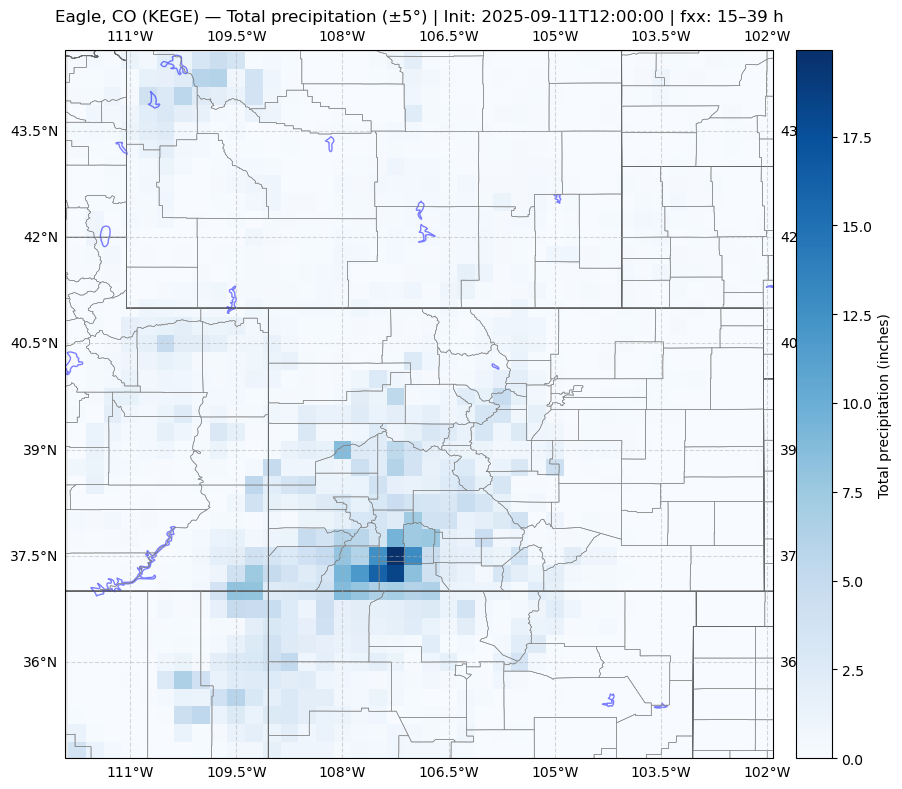

In [16]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader as shpreader

# Fetch gridded total precipitation for the same steps, sum over the steps and plot a subset +/-5° around the point
ds_tp = H_ifs.xarray(":tp:", backend_kwargs={'decode_times': False})
da_tp = ds_tp['tp'] if isinstance(ds_tp, xr.Dataset) else ds_tp

# Sum accumulated precipitation over the step dimension to get total (units: meters)
da_total = da_tp.sum(dim='step')
da_total_in = da_total * 39.3701  # Convert meters -> inches

# Center from points dataframe
center_lon = float(points.longitude.iloc[0])
center_lat = float(points.latitude.iloc[0])
lon0, lon1 = center_lon - 5.0, center_lon + 5.0
lat0, lat1 = center_lat - 5.0, center_lat + 5.0

# Normalize longitude to -180..180 if needed
if da_total_in.longitude.max() > 180:
    lons = ((da_total_in.longitude + 180) % 360) - 180
    da_total_in = da_total_in.assign_coords(longitude=lons).sortby('longitude')

# Subset using boolean indexing to avoid issues with coordinate ordering
da_sel = da_total_in.where(
    (da_total_in.longitude >= min(lon0, lon1)) & (da_total_in.longitude <= max(lon0, lon1)),
    drop=True
)
da_sel = da_sel.where(
    (da_sel.latitude >= min(lat0, lat1)) & (da_sel.latitude <= max(lat0, lat1)),
    drop=True
)

# Plot with cartopy for geographic features
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
# Use xarray's built-in pcolormesh plotting (handles lat/lon coords)
c = da_sel.plot.pcolormesh(
    ax=ax, x='longitude', y='latitude', cmap='Blues', shading='auto', add_colorbar=False, transform=ccrs.PlateCarree()
)
cb = fig.colorbar(c, ax=ax, orientation='vertical', pad=0.02)
cb.set_label('Total precipitation (inches)')

# Add geographic features
ax.add_feature(cfeature.BORDERS, linestyle='--', edgecolor='black', linewidth=0.8)
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.6)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.add_feature(cfeature.LAKES, edgecolor='blue', facecolor='none', alpha=0.5)

# Add county boundaries using a shapefile
shapefile = shpreader.natural_earth(resolution='10m', category='cultural', name='admin_2_counties')
counties = shpreader.Reader(shapefile).geometries()
ax.add_geometries(counties, ccrs.PlateCarree(), edgecolor='gray', facecolor='none', linewidth=0.4)

# Set title and labels
ax.set_title(f"{cityName} — Total precipitation (±5°) | Init: {pd.Timestamp(init_ifs).isoformat()} | fxx: {fxx_ifs[0]}–{fxx_ifs[-1]} h")
ax.set_extent([min(lon0, lon1), max(lon0, lon1), min(lat0, lat1), max(lat0, lat1)], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# IFS Ens

## Herbie

In [6]:
from functions import *   # get_latest_forecast_cycle, calculate_forecast_range, convert_time_to_datetime64
from herbie import FastHerbie
import pandas as pd
import numpy as np
import xarray as xr
import warnings

# Suppress the specific FutureWarning message from cfgrib
warnings.filterwarnings(
    "ignore",
    # message="In a future version of xarray the default value for compat will change",
    message="In*",
    category=FutureWarning
)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# xr.set_options(use_new_combine_kwarg_defaults=True)

# single point (longitude, latitude)
cityName = "Loveland, CO (KFNL)"
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
# cityName = 'Memphis, TN (KMEM)'
# points = pd.DataFrame({"longitude": [-90.04898], "latitude": [35.14953]})
print("Fetching IFS Ens data...")

init_ifs = get_latest_forecast_cycle(model="IFS")
fxx_ifs = calculate_forecast_range(init_ifs, model="IFS")[:1]  # limit to first 24h for testing
H_ifs = FastHerbie([init_ifs], model="ifs", product="enfo", fxx=fxx_ifs)


Fetching IFS Ens data...


In [8]:
H_ifs.inventory(":2t:")
# H_ifs.inventory(":2t:sfc:39:g:0001:od:pf:enfo")

,grib_message,start_byte,end_byte,range,reference_time,valid_time,step,param,levelist,levtype,number,domain,expver,class,type,stream,search_this,FILE
0,346,264600903,265256968,264600903-265256968,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,39,g,0001,od,pf,enfo,:2t:sfc:39:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
1,354,269963118,270617386,269963118-270617386,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,31,g,0001,od,pf,enfo,:2t:sfc:31:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
2,355,270617386,271272866,270617386-271272866,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,1,g,0001,od,pf,enfo,:2t:sfc:1:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
3,374,283233740,283889686,283233740-283889686,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,35,g,0001,od,pf,enfo,:2t:sfc:35:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
4,385,291804931,292461372,291804931-292461372,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,17,g,0001,od,pf,enfo,:2t:sfc:17:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
5,392,295559073,296213259,295559073-296213259,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,24,g,0001,od,pf,enfo,:2t:sfc:24:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
6,393,296213259,296870923,296213259-296870923,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,20,g,0001,od,pf,enfo,:2t:sfc:20:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
7,416,317575123,318232961,317575123-318232961,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,28,g,0001,od,pf,enfo,:2t:sfc:28:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
8,454,356431661,357088659,356431661-357088659,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,13,g,0001,od,pf,enfo,:2t:sfc:13:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...
9,465,367285426,367942180,367285426-367942180,2025-09-16,2025-09-17 06:00:00,1 days 06:00:00,2t,NaN,sfc,5,g,0001,od,pf,enfo,:2t:sfc:5:g:0001:od:pf:enfo,https://ecmwf-forecasts.s3.eu-central-1.amazon...


In [10]:
ds = H_ifs.xarray(":2t:", backend_kwargs={'decode_times': False})


AttributeError: 'list' object has no attribute 'step'

In [11]:
# inspect what matches first
print("Inventory for :2t:")
print(H_ifs.inventory(":2t:"))

# robustly load and concat (handles xarray.Dataset or lists returned by individual H.xarray calls)
import xarray as xr

ds_list = []
for H in H_ifs.file_exists:
    try:
        d = H.xarray(":2t:", backend_kwargs={'decode_times': False})
        # some H.xarray() return a Dataset, others return a list -> normalize
        if isinstance(d, list):
            ds_list.extend(d)
        else:
            ds_list.append(d)
    except Exception as exc:
        print(f"Warning loading {H!r}: {exc}")

if not ds_list:
    raise RuntimeError("No datasets loaded for :2t:")

# if elements are DataArrays, convert to Datasets first (optional)
ds_list = [xr.Dataset(d) if isinstance(d, xr.DataArray) else d for d in ds_list]

# concatenate along time/step as appropriate
try:
    ds = xr.concat(ds_list, dim="time")
except Exception:
    # try concatenating along 'step' if time fails
    ds = xr.concat(ds_list, dim="step")

print(ds)

Inventory for :2t:
    grib_message  start_byte    end_byte                  range  \
0            346   264600903   265256968    264600903-265256968   
1            354   269963118   270617386    269963118-270617386   
2            355   270617386   271272866    270617386-271272866   
3            374   283233740   283889686    283233740-283889686   
4            385   291804931   292461372    291804931-292461372   
5            392   295559073   296213259    295559073-296213259   
6            393   296213259   296870923    296213259-296870923   
7            416   317575123   318232961    317575123-318232961   
8            454   356431661   357088659    356431661-357088659   
9            465   367285426   367942180    367285426-367942180   
10          1339  1079743475  1080400500  1079743475-1080400500   
11          1344  1083533872  1084191604  1083533872-1084191604   
12          1351  1088852358  1089511271  1088852358-1089511271   
13          1353  1090919191  1091576375  1

ValueError: 'number' must have either an index or no index in all datasets, found 1/2 datasets with an index.

In [12]:
ds_list

[<xarray.Dataset> Size: 208MB
 Dimensions:              (number: 50, latitude: 721, longitude: 1440)
 Coordinates:
   * number               (number) int64 400B 1 2 3 4 5 6 7 ... 45 46 47 48 49 50
     time                 int64 8B 1757980800
     step                 timedelta64[ns] 8B 1 days 06:00:00
     heightAboveGround    float64 8B 2.0
   * latitude             (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
   * longitude            (longitude) float64 12kB -180.0 -179.8 ... 179.5 179.8
     valid_time           float64 8B 1.758e+09
     gribfile_projection  object 8B None
 Data variables:
     t2m                  (number, latitude, longitude) float32 208MB 266.9 .....
 Attributes:
     GRIB_edition:            2
     GRIB_centre:             ecmf
     GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
     GRIB_subCentre:          0
     Conventions:             CF-1.7
     institution:             European Centre for Medium-Range Weather Fore

## ECMWF

In [ ]:
from ecmwf.opendata import Client

client = Client(source="ecmwf")

parameters = ['2t']#,'tp']
# filename = 'medium-ens-2t.grib'
# filename

client.retrieve(
    # time=0,
    stream="enfo",
    type="em",
    step=24,
    # param=parameters,
    target="medium-ens-2t.grib2",
)


In [11]:
import xarray as xr
xr.open_dataset("medium-ens-2t.grib2", engine="cfgrib")

skipping variable: paramId==10 shortName='ws'
Traceback (most recent call last):
  File "/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cfgrib/dataset.py", line 725, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cfgrib/dataset.py", line 641, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([850., 500., 250.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([850., 250.]))
skipping variable: paramId==156 shortName='gh'
Traceback (most recent call last):
  File "/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/cfgrib/dataset.py", line 725, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~

<xarray.Dataset> Size: 17MB
Dimensions:        (isobaricInhPa: 3, latitude: 721, longitude: 1440)
Coordinates:
    time           datetime64[ns] 8B ...
    step           timedelta64[ns] 8B ...
  * isobaricInhPa  (isobaricInhPa) float64 24B 850.0 500.0 250.0
  * latitude       (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude      (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
    valid_time     datetime64[ns] 8B ...
    meanSea        float64 8B ...
Data variables:
    t              (isobaricInhPa, latitude, longitude) float32 12MB ...
    msl            (latitude, longitude) float32 4MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-09-16T14:58 GRIB to CDM+CF via cfgrib-0.9.1...

# Preivous day forecasts - HRRR

In [16]:
# Minimal script: fetch HRRR forecasts initialized on the prior day for the previous two target dates
# Paste into a new .py or notebook cell and run.

from datetime import timezone
import pandas as pd
from herbie import FastHerbie
from functions import calculate_forecast_range
import json, pprint

# single point to summarize (lon, lat)
points = pd.DataFrame({"longitude": [-105.004186], "latitude": [40.451685]})
site_name = "Loveland, CO (KFNL)"

def init_for_target_date(target_date):
    """For a target date (pd.Timestamp, UTC midnight), return the HRRR init on the prior day (18Z)."""
    prior_day = (target_date - pd.Timedelta(days=1))#.tz_localize('UTC')
    init = prior_day.replace(hour=18, minute=0, second=0, microsecond=0)
    # return tz-naive to match existing codebase expectations
    return pd.Timestamp(init).tz_localize(None)

def fetch_hrrr_metrics(init_ts):
    """Fetch HRRR for a given init (pd.Timestamp tz-naive) and return summary metrics."""
    try:
        fxx = calculate_forecast_range(init_ts, model="HRRR")
        H = FastHerbie([init_ts], model="hrrr", product="sfc", fxx=fxx)

        # 2 m temperature (K -> F), skip first timestep as in existing workflows
        t2m = H.xarray("TMP:2 m above", backend_kwargs={'decode_times': False}
                       ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)[1:]
        t2m_f = (t2m - 273.15) * 1.8 + 32
        tmax = float(t2m_f.max().values)
        tmin = float(t2m_f.min().values)

        # 10 m wind (HRRR :WIND / si10) -> max in knots
        si10 = H.xarray(":WIND", backend_kwargs={'decode_times': False}
                        ).herbie.pick_points(points, method="nearest")['max_10si'].sel(point=0)[1:]
        wind_max_kt = float(si10.max().values) * 1.94384

        # accumulated precipitation (APCP), convert to inches (match existing code)
        tp = H.xarray("APCP", backend_kwargs={'decode_times': False}
                      ).herbie.pick_points(points, method="nearest")['tp'].sel(point=0)
        tp_in = tp * 0.0393701
        # subtract first timestep to get step-accumulation over the requested window
        tp_step = tp_in[1:] - tp_in[0]
        precip_in = float(tp_step.max().values)

        return {
            "init_utc": str(init_ts),
            "tmax_f": round(tmax, 2),
            "tmin_f": round(tmin, 2),
            "wind_max_kt": round(wind_max_kt, 2),
            "precip_in": round(precip_in, 3),
        }
    except Exception as exc:
        return {"init_utc": str(init_ts), "error": str(exc)}

def main_previous_two_days():
    # target dates are UTC midnights for yesterday and day-before-yesterday
    now_utc = pd.Timestamp.utcnow().normalize()
    targets = [now_utc - pd.Timedelta(days=1), now_utc - pd.Timedelta(days=2)]

    results = {}
    for tgt in targets:
        init_ts = init_for_target_date(tgt).tz_localize(None)
        print(f"Requesting HRRR init {init_ts} for target date {tgt.date()}")
        results[str(tgt.date())] = fetch_hrrr_metrics(init_ts)

    return results

if __name__ == "__main__":
    metrics = main_previous_two_days()
    pprint.pprint(metrics)
    print(json.dumps(metrics, indent=2))

Requesting HRRR init 2025-09-14 18:00:00 for target date 2025-09-15
👨🏻‍🏭 Created directory: [/Users/jglarson/data/hrrr/20250914]
Requesting HRRR init 2025-09-13 18:00:00 for target date 2025-09-14
👨🏻‍🏭 Created directory: [/Users/jglarson/data/hrrr/20250913]
{'2025-09-14': {'init_utc': '2025-09-13 18:00:00',
                'precip_in': 0.171,
                'tmax_f': 73.51,
                'tmin_f': 52.62,
                'wind_max_kt': 14.13},
 '2025-09-15': {'init_utc': '2025-09-14 18:00:00',
                'precip_in': 0.001,
                'tmax_f': 84.48,
                'tmin_f': 47.94,
                'wind_max_kt': 17.0}}
{
  "2025-09-15": {
    "init_utc": "2025-09-14 18:00:00",
    "tmax_f": 84.48,
    "tmin_f": 47.94,
    "wind_max_kt": 17.0,
    "precip_in": 0.001
  },
  "2025-09-14": {
    "init_utc": "2025-09-13 18:00:00",
    "tmax_f": 73.51,
    "tmin_f": 52.62,
    "wind_max_kt": 14.13,
    "precip_in": 0.171
  }
}


Timestamp('2025-09-16 00:00:00+0000', tz='UTC')